In [8]:
!pip install ultralytics

from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [9]:
import os

base_dir = '/content/drive/My Drive/traffic-road-object-detection-polish-12k/road_detection/road_detection'
train_dir = os.path.join(base_dir, 'train')
val_dir = os.path.join(base_dir, 'valid')
test_dir = os.path.join(base_dir, 'test')

assert os.path.exists(base_dir), f"Base directory not found"
assert os.path.exists(train_dir), f"Train directory not found: {train_dir}"
assert os.path.exists(val_dir), f"Validation directory not found: {val_dir}"
assert os.path.exists(test_dir), f"Test directory not found: {test_dir}"

# traffic-road-object-detection-polish-12k/road_detection/road_detection

In [10]:
import os

for root, dirs, files in os.walk(base_dir):
    print(f"Root: {root}")
    print(f"Directories: {dirs}")
    print(f"Files: {len(files)} files found\n")


Root: /content/drive/My Drive/traffic-road-object-detection-polish-12k/road_detection/road_detection
Directories: ['test', 'valid', 'train']
Files: 0 files found

Root: /content/drive/My Drive/traffic-road-object-detection-polish-12k/road_detection/road_detection/test
Directories: ['images', 'labels']
Files: 1 files found

Root: /content/drive/My Drive/traffic-road-object-detection-polish-12k/road_detection/road_detection/test/images
Directories: []
Files: 484 files found

Root: /content/drive/My Drive/traffic-road-object-detection-polish-12k/road_detection/road_detection/test/labels
Directories: []
Files: 484 files found

Root: /content/drive/My Drive/traffic-road-object-detection-polish-12k/road_detection/road_detection/valid
Directories: ['labels', 'images']
Files: 1 files found

Root: /content/drive/My Drive/traffic-road-object-detection-polish-12k/road_detection/road_detection/valid/labels
Directories: []
Files: 935 files found

Root: /content/drive/My Drive/traffic-road-object-de

First Image Shape: (480, 640, 3)
First Image Boxes: [[538, 245, 564, 288], [445, 340, 591, 475], [314, 338, 360, 392], [379, 340, 415, 379], [366, 339, 387, 365], [338, 299, 346, 311], [353, 300, 359, 311], [323, 298, 329, 311]]
First Image Class IDs: [1, 0, 0, 0, 0, 2, 2, 7]


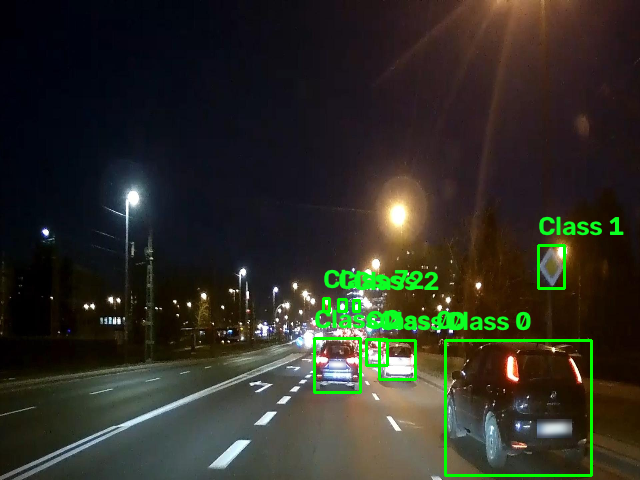

In [11]:
import os
import cv2
from google.colab.patches import cv2_imshow
import numpy as np

# Paths to the dataset directories
train_images_path = os.path.join(test_dir, "images")
train_labels_path = os.path.join(test_dir, "labels")

img_width, img_height = 640, 480  # Assumed image size (adjust based on your actual image size)

# Helper function to parse a single YOLO label line
def parse_yolo_label(label_line):
    label_parts = label_line.strip().split()
    class_id = int(label_parts[0])
    center_x = float(label_parts[1])
    center_y = float(label_parts[2])
    width = float(label_parts[3])
    height = float(label_parts[4])
    return class_id, center_x, center_y, width, height

# Convert YOLO format to bounding box coordinates in image pixel values
def yolo_to_image_coords(center_x, center_y, width, height, img_width, img_height):
    box_x1 = int((center_x - width / 2) * img_width)
    box_y1 = int((center_y - height / 2) * img_height)
    box_x2 = int((center_x + width / 2) * img_width)
    box_y2 = int((center_y + height / 2) * img_height)
    return box_x1, box_y1, box_x2, box_y2

# Load images and corresponding labels
def load_data(images_path, labels_path):
    images = []
    boxes = []
    class_ids = []

    for image_file in os.listdir(images_path):
        if image_file.endswith('.jpg') or image_file.endswith('.png'):
            # Load image
            image_path = os.path.join(images_path, image_file)
            image = cv2.imread(image_path)
            image = cv2.resize(image, (img_width, img_height))  # Adjust size

            # Append image to list
            images.append(image)

            # Load corresponding label
            label_file = os.path.splitext(image_file)[0] + '.txt'
            label_path = os.path.join(labels_path, label_file)

            with open(label_path, 'r') as file:
                label_data = file.readlines()
                image_boxes = []
                image_class_ids = []

                for label_line in label_data:
                    class_id, center_x, center_y, width, height = parse_yolo_label(label_line)
                    box_x1, box_y1, box_x2, box_y2 = yolo_to_image_coords(center_x, center_y, width, height, img_width, img_height)

                    # Append box and class_id to respective lists
                    image_boxes.append([box_x1, box_y1, box_x2, box_y2])
                    image_class_ids.append(class_id)

                boxes.append(image_boxes)
                class_ids.append(image_class_ids)

    return np.array(images), boxes, class_ids

# Load training data
train_images, train_boxes, train_class_ids = load_data(train_images_path, train_labels_path)

# Example: Inspect the first image, boxes, and classes
print("First Image Shape:", train_images[0].shape)
print("First Image Boxes:", train_boxes[0])
print("First Image Class IDs:", train_class_ids[0])

# Visualize an image with bounding boxes drawn
def visualize_image_with_boxes(image, boxes, class_ids):
    for (box, class_id) in zip(boxes, class_ids):
        x1, y1, x2, y2 = box
        # Draw rectangle and class id
        cv2.rectangle(image, (x1, y1), (x2, y2), (0, 255, 0), 2)
        cv2.putText(image, f'Class {class_id}', (x1, y1 - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (36,255,12), 2)

    # cv2.imshow("Image with Bounding Boxes", image)
    cv2_imshow(image)

# Example visualization
visualize_image_with_boxes(train_images[0], train_boxes[0], train_class_ids[0])


In [14]:
from ultralytics import YOLO

model = YOLO("/content/drive/MyDrive/Krithik Prasad/Project Notebooks/best.pt");  # load a custom model

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings



0: 480x640 3 cars, 1 pedestrian, 395.9ms
Speed: 4.3ms preprocess, 395.9ms inference, 0.9ms postprocess per image at shape (1, 3, 480, 640)


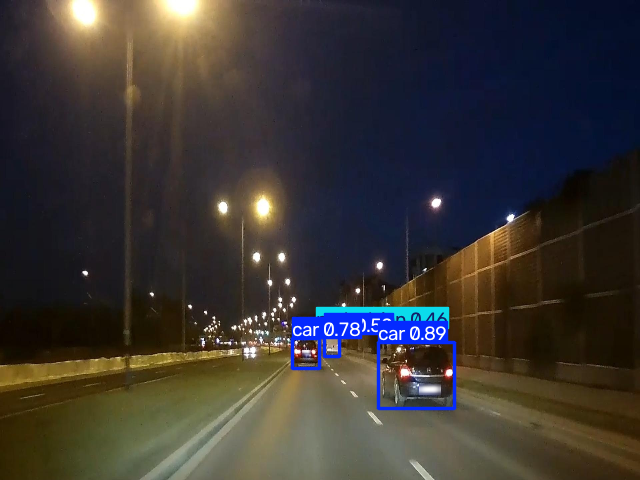

In [22]:
import random

image_index = random.randint(0, len(train_images) - 1)
results = model.predict(train_images[image_index])
cv2_imshow(results[0].plot())